# Bab 5: Linear Models and Regularization

Notebook ini merangkum Bab 5 buku *scikit-learn Cookbook* (Third Edition) karya John Sukup. Bab ini membahas regresi linear dan variasi-variasinya: Ridge, Lasso, ElasticNet, serta bagaimana regularisasi membantu mencegah overfitting, ditutup dengan polynomial regression dan spline interpolation untuk menangani hubungan non-linear.

Semua kode di notebook ini sudah dijalankan, jadi outputnya langsung terlihat begitu file dibuka.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(123)
pd.set_option("display.precision", 4)

## 1. Pengantar Linear Models

Linear regression mencoba menemukan hubungan matematis antar titik data yang bisa direpresentasikan sebagai persamaan garis. Kita akan membuat dataset sintetis dengan `make_regression()` yang sengaja dibuat punya multikolinearitas tinggi (banyak fitur saling berkorelasi) dan sedikit non-linearitas, supaya lebih menantang dan realistis.

In [2]:
from sklearn.datasets import make_regression

X, y = make_regression(
    n_samples=1000, n_features=100, n_informative=10,
    noise=20, random_state=123,
)

# Buat separuh fitur saling berkorelasi, mensimulasikan multikolinearitas
for i in range(50, 100):
    X[:, i] = X[:, i - 50] + np.random.normal(0, 0.1, size=1000)

feature_names = [f"feature_{i}" for i in range(100)]
X_plot = X[:, 0].reshape(-1, 1)

# Tambahkan non-linearitas dan buat skala koefisien bervariasi lebar
y = y * 1000
y = y + np.sin(X_plot.ravel()) * 150 + np.exp(X_plot.ravel() / 10)

df = pd.DataFrame(X, columns=feature_names)
df["target"] = y

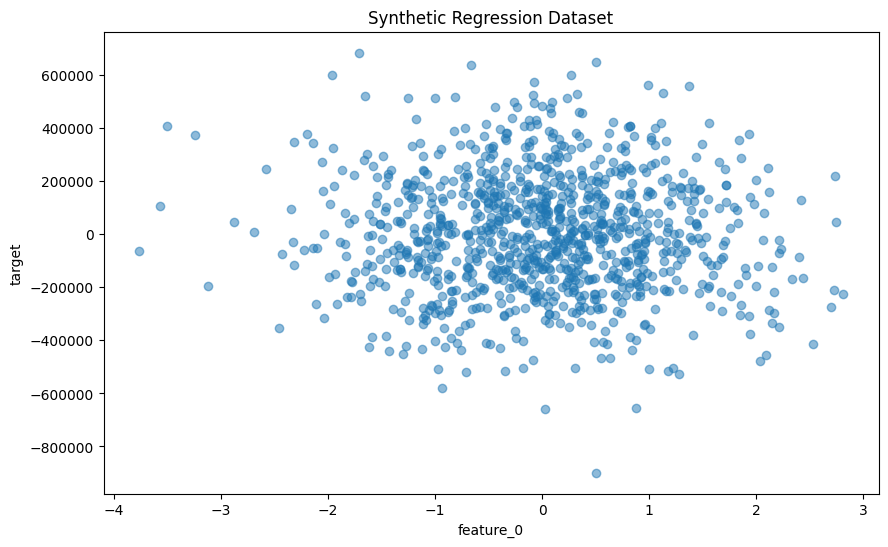

In [3]:
plt.figure(figsize=(10, 6))
plt.scatter(X_plot, y, alpha=0.5)
plt.xlabel("feature_0")
plt.ylabel("target")
plt.title("Synthetic Regression Dataset")
plt.show()

Perhatikan bahwa visualisasi ini hanya menampilkan satu fitur (`feature_0`) dari total 100 fitur yang ada, sekadar untuk kebutuhan visualisasi 2D. Sebaran datanya terlihat sangat acak, meski secara keseluruhan masih mendekati distribusi normal.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=123
)

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

y_pred = linear_model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"Mean Squared Error: {mse:.2f}")
print(f"R-squared: {r2:.2f}")

Mean Squared Error: 46550591070.53
R-squared: 0.06


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(


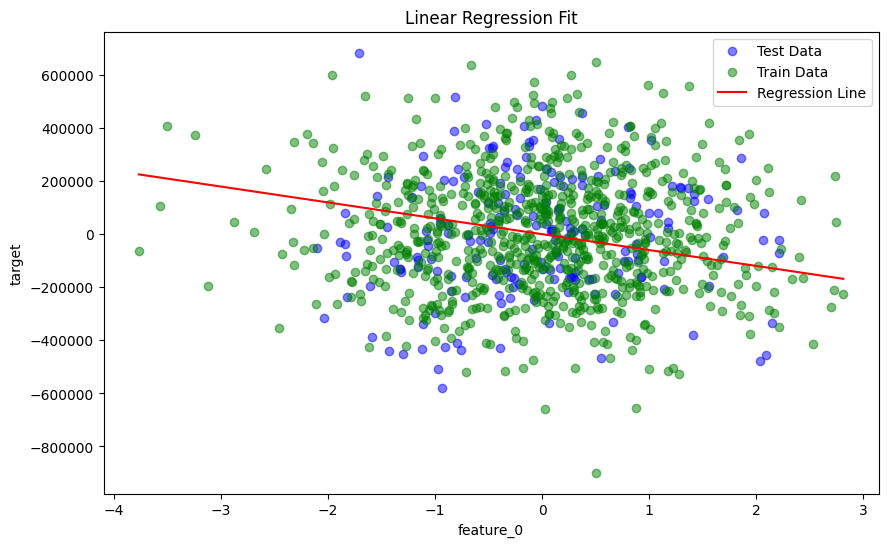

In [5]:
plt.figure(figsize=(10, 6))
plt.scatter(X_test[:, 0], y_test, color="blue", alpha=0.5, label="Test Data")
plt.scatter(X_train[:, 0], y_train, color="green", alpha=0.5, label="Train Data")

X_line = np.linspace(df["feature_0"].min(), df["feature_0"].max(), 100).reshape(-1, 1)
X_line_full = np.zeros((100, len(feature_names)))
X_line_full[:, 0] = X_line.ravel()
y_line = linear_model.predict(pd.DataFrame(X_line_full, columns=feature_names))
plt.plot(X_line, y_line, color="red", label="Regression Line")

plt.xlabel("feature_0")
plt.ylabel("target")
plt.title("Linear Regression Fit")
plt.legend()
plt.show()

### Cara Kerja Linear Regression

Linear regression memodelkan hubungan antara variabel dependen (target) dan satu atau lebih variabel independen (fitur), dengan asumsi hubungannya linear:

y = β0 + β1x1 + β2x2 + ... + βpxp + ε

Di sini, y adalah nilai prediksi, β0 adalah intercept, βi adalah koefisien tiap fitur, xi adalah nilai fitur, dan ε adalah error term.

**Fitted values** adalah nilai prediksi model untuk tiap data, sementara **residuals** adalah selisih antara nilai asli dan fitted value-nya. Residual inilah yang nanti jadi dasar untuk mengevaluasi seberapa baik model cocok dengan data, dan akan sering muncul lagi di bagian regularisasi berikutnya.

## 2. Ridge dan Lasso Regression

Ridge dan Lasso regression meningkatkan performa linear regression lewat **regularisasi**: menambahkan penalti ke loss function supaya model tidak menjadi terlalu kompleks (overfitting). Kita akan memakai dataset yang sama dari bagian sebelumnya untuk membandingkan ketiganya.

In [6]:
from sklearn.linear_model import Ridge, Lasso

ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train, y_train)

lasso_model = Lasso(alpha=10.0, max_iter=10000, tol=0.001)
lasso_model.fit(X_train, y_train)

y_pred_ridge = ridge_model.predict(X_test)
y_pred_lasso = lasso_model.predict(X_test)
y_pred_linear = linear_model.predict(X_test)

In [7]:
metrics = {
    "Model": ["Ridge Regression", "Lasso Regression", "Linear Regression"],
    "Mean Squared Error": [
        mean_squared_error(y_test, y_pred_ridge),
        mean_squared_error(y_test, y_pred_lasso),
        mean_squared_error(y_test, y_pred_linear),
    ],
    "R-squared": [
        r2_score(y_test, y_pred_ridge),
        r2_score(y_test, y_pred_lasso),
        r2_score(y_test, y_pred_linear),
    ],
}

metrics_df = pd.DataFrame(metrics)
metrics_df = metrics_df.sort_values("Mean Squared Error", ascending=True)
metrics_df["Mean Squared Error"] = metrics_df["Mean Squared Error"].map("{:.2f}".format)
metrics_df["R-squared"] = metrics_df["R-squared"].map("{:.2f}".format)
metrics_df

,Model,Mean Squared Error,R-squared
0,Ridge Regression,45341091794.40,0.09
1,Lasso Regression,46377111017.93,0.07
2,Linear Regression,46550591070.53,0.06


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but Ridge was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but Lasso was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(


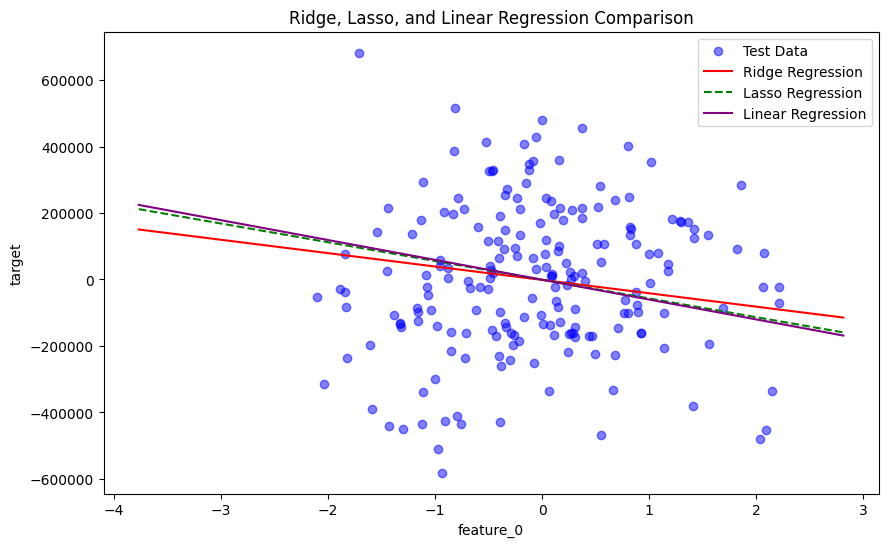

In [8]:
plt.figure(figsize=(10, 6))
plt.scatter(X_test[:, 0], y_test, color="blue", alpha=0.5, label="Test Data")

X_line_full = np.zeros((100, len(feature_names)))
X_line_full[:, 0] = X_line.ravel()
X_line_df = pd.DataFrame(X_line_full, columns=feature_names)

y_line_ridge = ridge_model.predict(X_line_df)
y_line_lasso = lasso_model.predict(X_line_df)
y_line_linear = linear_model.predict(X_line_df)

plt.plot(X_line, y_line_ridge, color="red", label="Ridge Regression")
plt.plot(X_line, y_line_lasso, color="green", linestyle="--", label="Lasso Regression")
plt.plot(X_line, y_line_linear, color="purple", label="Linear Regression")
plt.xlabel("feature_0")
plt.ylabel("target")
plt.title("Ridge, Lasso, and Linear Regression Comparison")
plt.legend()
plt.show()

Perbedaan ketiganya di sini cukup kecil, tapi dalam kasus nyata, selisih sekecil apa pun bisa berdampak signifikan tergantung konteks bisnisnya.

### Cara Kerja Ridge dan Lasso

- **Ridge regression**: menambahkan penalti L2 ke loss function OLS: Loss = Σ(yi - ŷi)² + α Σβj². Penalti ini mendorong koefisien jadi kecil untuk mengurangi kompleksitas model dan mencegah overfitting, tapi tidak pernah membuat koefisien jadi persis nol.
- **Lasso regression**: menambahkan penalti L1: Loss = Σ(yi - ŷi)² + α Σ|βj|. Penalti L1 tidak hanya mencegah overfitting, tapi juga melakukan seleksi fitur dengan mendorong sebagian koefisien jadi persis nol, efektif menghilangkannya dari model.

Ridge cocok kalau kita ingin mempertahankan semua fitur tapi mengurangi pengaruhnya lewat regularisasi. Lasso lebih cocok kalau kita menduga banyak fitur yang tidak relevan atau redundan, karena bisa menghilangkannya sepenuhnya dari model.

## 3. ElasticNet dan Regularisasi

ElasticNet adalah kombinasi dari Ridge dan Lasso, menggabungkan kekuatan keduanya untuk menangani berbagai jenis data. Parameter `alpha` mengatur kekuatan regularisasi secara keseluruhan, sementara `l1_ratio` mengatur proporsi antara regularisasi Ridge dan Lasso.

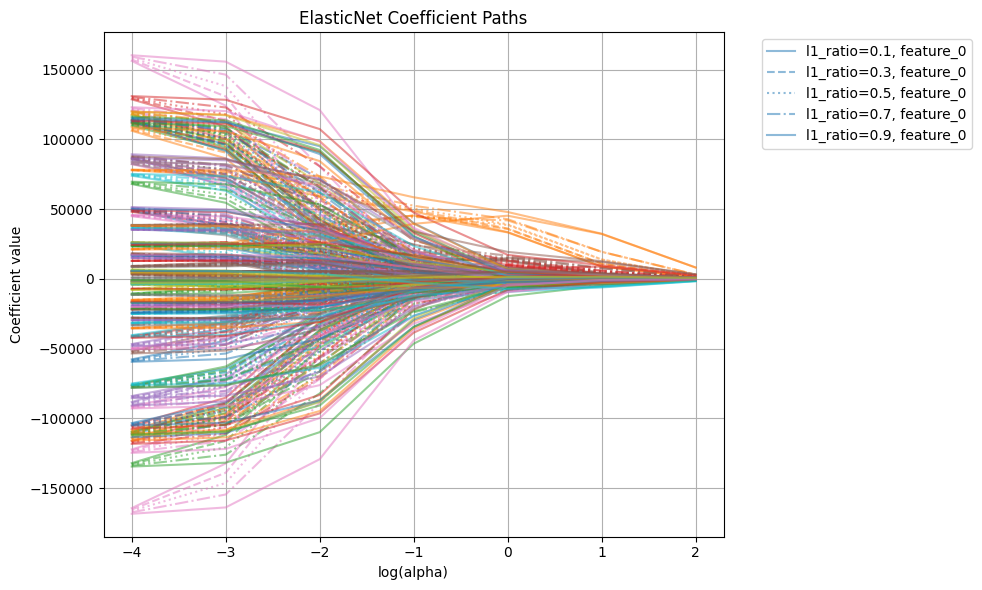

In [9]:
from sklearn.linear_model import ElasticNet

alphas = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]
l1_ratios = [0.1, 0.3, 0.5, 0.7, 0.9]

coef_paths = []

plt.figure(figsize=(10, 6))
for l1_ratio in l1_ratios:
    coefs = []
    for alpha in alphas:
        elastic_model = ElasticNet(
            alpha=alpha, l1_ratio=l1_ratio, random_state=123,
            max_iter=10000, tol=1e-4,
        )
        elastic_model.fit(X_train, y_train)
        coefs.append(elastic_model.coef_)
    coef_paths.append(np.array(coefs))

    for feature_idx in range(X_train.shape[1]):
        plt.plot(
            np.log10(alphas), np.array(coefs)[:, feature_idx],
            label=(f"l1_ratio={l1_ratio}, feature_{feature_idx}" if feature_idx == 0 else ""),
            alpha=0.5,
            linestyle=["solid", "dashed", "dotted", "dashdot", "-"][l1_ratios.index(l1_ratio)],
        )

plt.xlabel("log(alpha)")
plt.ylabel("Coefficient value")
plt.title("ElasticNet Coefficient Paths")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True)
plt.tight_layout()
plt.show()

Plot coefficient path ini menunjukkan bagaimana koefisien model (bobot fitur) berubah seiring kekuatan regularisasi (alpha) bervariasi:

- **Sumbu X (log(alpha))**: menunjukkan kekuatan regularisasi dalam skala logaritmik, dari sangat lemah (0.0001) sampai sangat kuat (100).
- **Sumbu Y (coefficient value)**: menunjukkan besarnya koefisien fitur. Kalau koefisiennya nol, berarti fitur itu sudah dihilangkan dari model.
- **Garis berbeda**: tiap garis merepresentasikan bagaimana koefisien satu fitur berubah di berbagai nilai alpha, dengan gaya garis berbeda untuk tiap nilai `l1_ratio`.

`l1_ratio` mengatur campuran antara regularisasi Ridge (L2) dan Lasso (L1): nilai mendekati 0.1 berperilaku lebih seperti Ridge (cenderung menyusutkan koefisien), sementara nilai mendekati 0.9 berperilaku lebih seperti Lasso (cenderung menghilangkan fitur sepenuhnya). Semakin besar alpha, koefisien secara umum semakin mengecil, dan sebagian bahkan menjadi tepat nol, tanda ElasticNet, seperti Ridge dan Lasso, juga melakukan seleksi fitur.

In [10]:
elastic_model = ElasticNet(alpha=1.0, l1_ratio=0.5, random_state=123, max_iter=10000, tol=1e-4)
elastic_model.fit(X_train, y_train)

elastic_pred = elastic_model.predict(X_test)
elastic_mse = mean_squared_error(y_test, elastic_pred)
elastic_r2 = r2_score(y_test, elastic_pred)

new_row = pd.DataFrame({
    "Model": ["ElasticNet Regression"],
    "Mean Squared Error": [elastic_mse],
    "R-squared": [elastic_r2],
})

# Bandingkan dengan tiga model sebelumnya (tanpa format string supaya bisa diurutkan dengan benar)
metrics_numeric = {
    "Model": ["Ridge Regression", "Lasso Regression", "Linear Regression"],
    "Mean Squared Error": [
        mean_squared_error(y_test, y_pred_ridge),
        mean_squared_error(y_test, y_pred_lasso),
        mean_squared_error(y_test, y_pred_linear),
    ],
    "R-squared": [
        r2_score(y_test, y_pred_ridge),
        r2_score(y_test, y_pred_lasso),
        r2_score(y_test, y_pred_linear),
    ],
}
metrics_df_full = pd.concat([pd.DataFrame(metrics_numeric), new_row], ignore_index=True)
metrics_df_full = metrics_df_full.sort_values("Mean Squared Error", ascending=True)
metrics_df_full

,Model,Mean Squared Error,R-squared
3,ElasticNet Regression,4.2617e+10,0.1438
0,Ridge Regression,4.5341e+10,0.0891
1,Lasso Regression,4.6377e+10,0.0683
2,Linear Regression,4.6551e+10,0.0648


ElasticNet sangat berguna untuk dataset berdimensi tinggi di mana banyak fitur mungkin tidak berkontribusi secara berarti terhadap prediksi, karena kemampuannya melakukan seleksi fitur otomatis dengan menyusutkan sebagian koefisien jadi nol, mirip Lasso, tapi tetap mempertahankan kestabilan Ridge saat fitur-fiturnya saling berkorelasi tinggi.

## 4. Teori dan Praktik Regularisasi

Regularisasi adalah teknik yang hampir selalu dipakai dalam aplikasi ML di dunia nyata. Inti idenya: menambahkan penalti ke loss function selama training, yang mencegah model menjadi terlalu kompleks atau terlalu bergantung pada fitur tertentu. Dengan begitu, model lebih fokus menangkap pola yang sesungguhnya ketimbang menghafal noise atau keunikan dari data training.

Tujuan utamanya adalah menyeimbangkan kompleksitas model dengan goodness of fit. Tanpa regularisasi, model bisa mencapai performa nyaris sempurna di data training dengan membentuk decision boundary yang terlalu rumit, tapi performanya di data baru yang belum pernah dilihat justru buruk.

Beberapa jenis regularisasi:

- **L1 (Lasso)**: menambahkan penalti berupa nilai absolut dari magnitude koefisien, menghasilkan model yang sparse dengan sebagian koefisien persis nol (seleksi fitur otomatis).
- **L2 (Ridge)**: menambahkan penalti berupa kuadrat dari magnitude koefisien, menyusutkan koefisien besar tapi tidak pernah membuatnya persis nol, sehingga semua fitur tetap berkontribusi.
- **ElasticNet**: menggabungkan keduanya, memberi keseimbangan antara seleksi fitur dan penyusutan koefisien.

Regularisasi berperan penting dalam **bias-variance trade-off**: menambahkan regularisasi biasanya sedikit menaikkan bias (karena model jadi lebih terbatas), tapi secara signifikan menurunkan variance (sensitivitas prediksi terhadap fluktuasi data training). Tujuannya mencari level regularisasi optimal yang meminimalkan error prediksi keseluruhan pada data baru.

## 5. Regresi dan Regularisasi: Menangani Hubungan Non-Linear

Kadang hubungan antara fitur dan target tidak benar-benar linear. Untuk kasus ini, kita bisa memakai polynomial regression atau spline interpolation, yang memperluas kemampuan regresi linear biasa untuk menangkap pola yang melengkung.

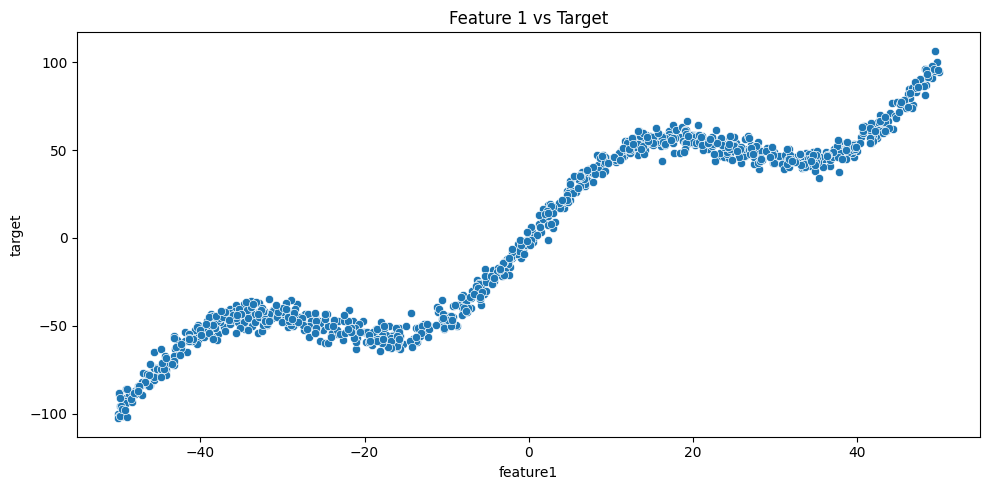

In [11]:
import seaborn as sns

n_samples = 1000
X_nl = np.random.uniform(-50, 50, (n_samples, 1))

# Target dengan komponen linear dan non-linear (gelombang sinus)
y_nl = (
    2 * X_nl[:, 0]
    + 27 * np.sin(X_nl[:, 0] / 8)
    + np.random.normal(0, 4, n_samples)
)

data_nl = pd.DataFrame(X_nl, columns=["feature1"])
data_nl["target"] = y_nl

plt.figure(figsize=(10, 5))
sns.scatterplot(data=data_nl, x="feature1", y="target")
plt.title("Feature 1 vs Target")
plt.tight_layout()
plt.show()

Dataset ini sengaja dibuat punya pola gelombang sinus yang jelas non-linear, sesuatu yang tidak bisa ditangkap dengan baik oleh garis lurus biasa.

### Polynomial Regression

Polynomial regression memperluas linear regression dengan menambahkan suku pangkat dari fitur (misalnya x², x³). Mari kita coba beberapa derajat polynomial berbeda dan bandingkan performanya.

In [12]:
from sklearn.preprocessing import PolynomialFeatures

X_nl_df = data_nl[["feature1"]]
y_nl_series = data_nl["target"]

degrees = [1, 2, 3, 4, 5]
results = []

for degree in degrees:
    poly = PolynomialFeatures(degree=degree)
    X_poly = poly.fit_transform(X_nl_df)

    X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
        X_poly, y_nl_series, test_size=0.2, random_state=123
    )

    poly_model = LinearRegression()
    poly_model.fit(X_train_p, y_train_p)

    y_pred_p = poly_model.predict(X_test_p)
    mse_p = mean_squared_error(y_test_p, y_pred_p)
    r2_p = r2_score(y_test_p, y_pred_p)

    results.append({"Degree": degree, "MSE": mse_p, "R2": r2_p})

results_df = pd.DataFrame(results)
results_df

,Degree,MSE,R2
0,1,339.1860,0.8732
1,2,343.2672,0.8717
2,3,291.9692,0.8908
3,4,293.4971,0.8903
4,5,49.2901,0.9816


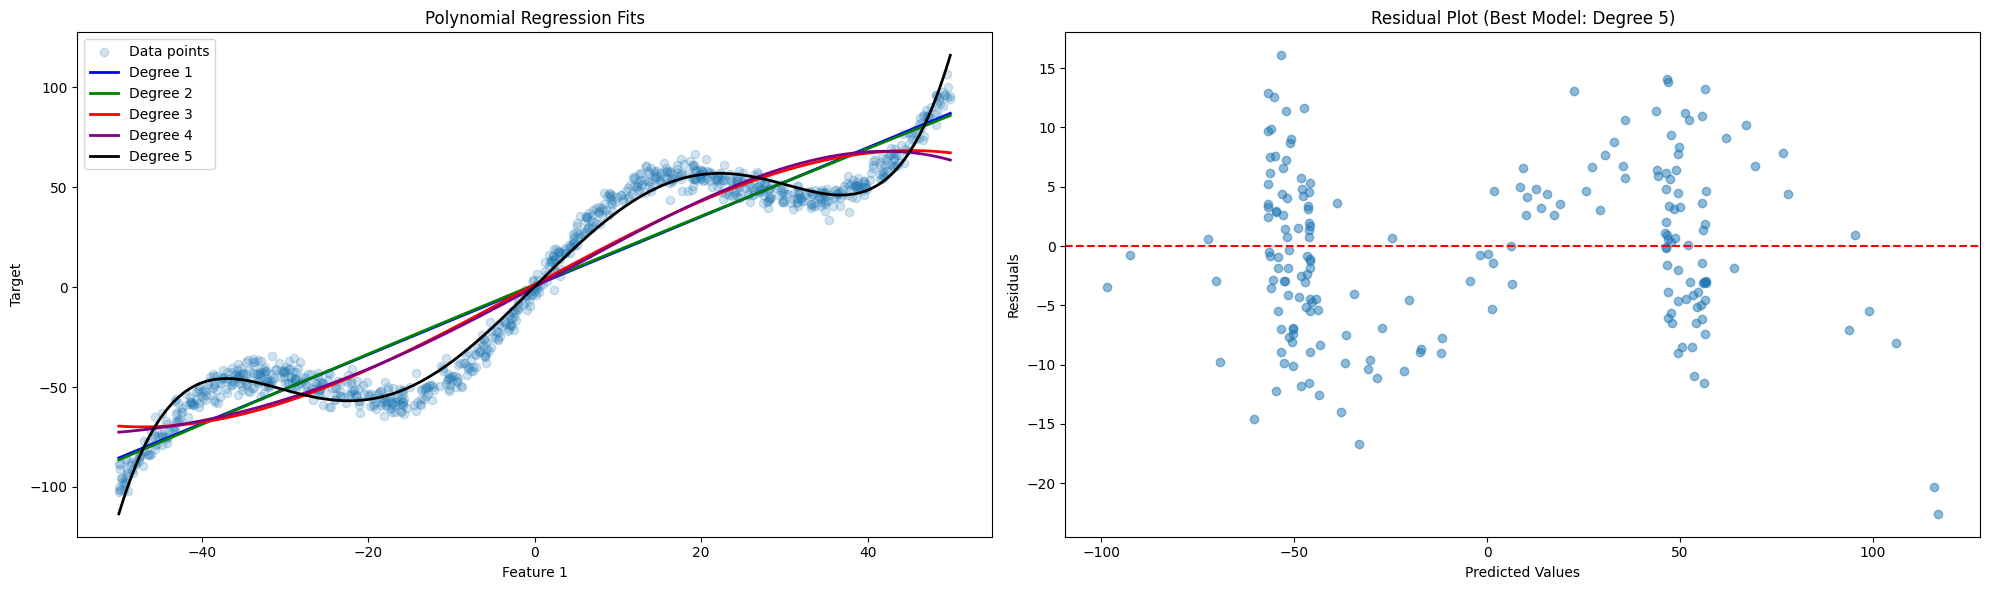

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 6))

ax1.scatter(X_nl_df["feature1"], y_nl_series, alpha=0.2, label="Data points")

X_plot_nl = np.linspace(
    X_nl_df["feature1"].min(), X_nl_df["feature1"].max(), 1000
).reshape(-1, 1)
colors = ["blue", "green", "red", "purple", "black"]

for degree, color in zip(degrees, colors):
    poly = PolynomialFeatures(degree=degree)
    X_plot_poly = poly.fit_transform(X_plot_nl)
    model = LinearRegression()
    model.fit(poly.fit_transform(X_nl_df), y_nl_series)
    y_plot = model.predict(X_plot_poly)
    ax1.plot(X_plot_nl, y_plot, label=f"Degree {degree}", color=color, linewidth=2)

ax1.set_xlabel("Feature 1")
ax1.set_ylabel("Target")
ax1.set_title("Polynomial Regression Fits")
ax1.legend(loc="upper left")

best_degree = results_df.loc[results_df["R2"].idxmax(), "Degree"]
best_poly = PolynomialFeatures(degree=int(best_degree))
X_poly_best = best_poly.fit_transform(X_nl_df)
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_poly_best, y_nl_series, test_size=0.2, random_state=123
)
best_model = LinearRegression()
best_model.fit(X_train_b, y_train_b)
y_pred_b = best_model.predict(X_test_b)
residuals = y_test_b - y_pred_b

ax2.scatter(y_pred_b, residuals, alpha=0.5)
ax2.axhline(y=0, color="r", linestyle="--")
ax2.set_xlabel("Predicted Values")
ax2.set_ylabel("Residuals")
ax2.set_title(f"Residual Plot (Best Model: Degree {best_degree})")

plt.tight_layout()
plt.show()

Polynomial regression bisa terlihat seperti sulap ketika bekerja dengan dataset non-linear, tapi tetap perlu waspada terhadap masalah lama yang sudah berulang kali kita bahas: overfitting. Kita tidak ingin model menangkap noise dalam data, karena tidak ada jaminan pola yang sama akan muncul lagi saat model diuji dengan data dunia nyata. Karena itu, memilih model terbaik tidak boleh hanya berdasarkan MSE dan R² semata.

### Spline Interpolation

Spline interpolation membuat kurva halus yang melewati sekumpulan titik data, dengan membagi data jadi beberapa segmen dan memasang polynomial di tiap segmen (piecewise polynomial), hasilnya mulus dan kontinu di titik-titik pertemuan segmen (disebut knot). `SplineTransformer()` di scikit-learn memungkinkan kita menentukan jumlah knot dan derajat polynomial untuk tiap segmen.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SplineTransformer was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SplineTransformer was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SplineTransformer was fitted with feature names
  warnings.warn(


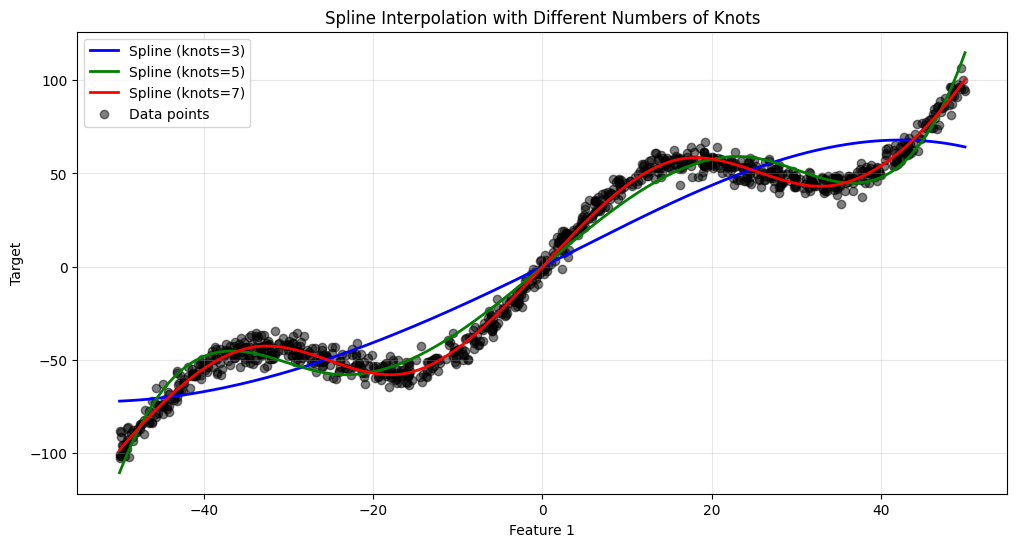

In [14]:
from sklearn.preprocessing import SplineTransformer
from sklearn.pipeline import make_pipeline

n_knots = [3, 5, 7]
plt.figure(figsize=(12, 6))

mse_scores = []
r2_scores = []

for n_knot, color in zip(n_knots, colors[: len(n_knots)]):
    spline = SplineTransformer(n_knots=n_knot, degree=3)
    model = make_pipeline(spline, LinearRegression())
    model.fit(X_nl_df, y_nl_series)

    y_pred_spline = model.predict(X_plot_nl)
    y_pred_train = model.predict(X_nl_df)

    mse = mean_squared_error(y_nl_series, y_pred_train)
    r2 = r2_score(y_nl_series, y_pred_train)
    mse_scores.append(mse)
    r2_scores.append(r2)

    plt.plot(X_plot_nl, y_pred_spline, label=f"Spline (knots={n_knot})", color=color, linewidth=2)

plt.scatter(X_nl_df, y_nl_series, color="black", alpha=0.5, label="Data points")
plt.xlabel("Feature 1")
plt.ylabel("Target")
plt.title("Spline Interpolation with Different Numbers of Knots")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [15]:
spline_metrics_df = pd.DataFrame({
    "Number of Knots": n_knots,
    "MSE": mse_scores,
    "R-squared": r2_scores,
})
spline_metrics_df

,Number of Knots,MSE,R-squared
0,3,264.6435,0.9053
1,5,54.3624,0.9805
2,7,17.3648,0.9938


Seiring bertambahnya jumlah knot pada spline regression, MSE cenderung menurun, menandakan model cocok semakin baik dengan data. Tapi, sama seperti polynomial regression, menambah fleksibilitas model (lewat lebih banyak knot) tetap perlu diimbangi kewaspadaan terhadap overfitting.

### Cara Kerja Polynomial Regression dan Spline

Polynomial regression memperluas linear regression dengan memasang persamaan polynomial ke data. Dengan mentransformasikan fitur input jadi suku-suku polynomial (seperti x² dan x³), teknik ini bisa menangkap hubungan non-linear antara variabel dependen dan independen:

y = β0 + β1x + β2x² + ... + βpxp + ε

Spline interpolation adalah metode yang lebih fleksibel untuk memasang piecewise polynomial ke titik data. Teknik ini memungkinkan transisi mulus antar segmen sambil tetap menjaga kontinuitas di titik batas segmen, sangat berguna untuk dataset kompleks yang menunjukkan tren non-linear.

Di luar polynomial dan spline dasar, ada juga teknik lebih canggih seperti B-spline atau natural spline untuk pemodelan hubungan non-linear yang lebih sofistikasi.

## 6. Latihan Praktis dengan Teknik Regularisasi

### Latihan 1: Implementasi Ridge Regression

Buat dataset sintetis baru dengan sedikit noise, lalu terapkan ridge regression dan evaluasi performanya.

Ridge Regression -> MSE: 227.25, R2: 0.9951


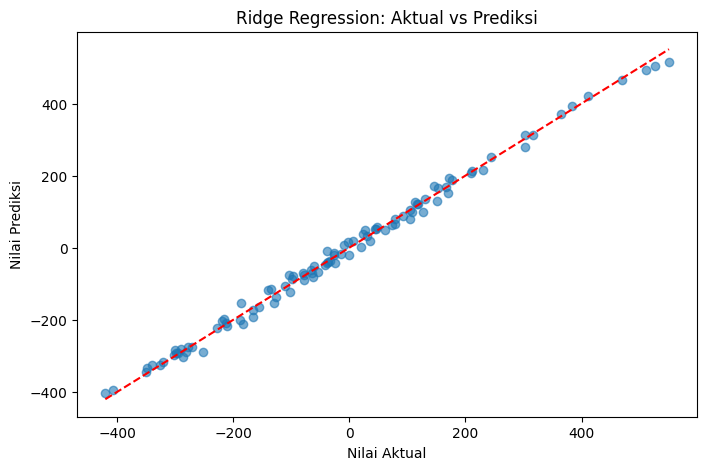

In [16]:
np.random.seed(123)

X_ex, y_ex = make_regression(n_samples=500, n_features=20, noise=15, random_state=123)

X_train_ex, X_test_ex, y_train_ex, y_test_ex = train_test_split(
    X_ex, y_ex, test_size=0.2, random_state=123
)

ridge_ex = Ridge(alpha=1.0)
ridge_ex.fit(X_train_ex, y_train_ex)

y_pred_ridge_ex = ridge_ex.predict(X_test_ex)
mse_ridge_ex = mean_squared_error(y_test_ex, y_pred_ridge_ex)
r2_ridge_ex = r2_score(y_test_ex, y_pred_ridge_ex)

print(f"Ridge Regression -> MSE: {mse_ridge_ex:.2f}, R2: {r2_ridge_ex:.4f}")

plt.figure(figsize=(8, 5))
plt.scatter(y_test_ex, y_pred_ridge_ex, alpha=0.6)
plt.plot(
    [y_test_ex.min(), y_test_ex.max()],
    [y_test_ex.min(), y_test_ex.max()],
    color="red", linestyle="--",
)
plt.xlabel("Nilai Aktual")
plt.ylabel("Nilai Prediksi")
plt.title("Ridge Regression: Aktual vs Prediksi")
plt.show()

### Latihan 2: Implementasi Lasso Regression

Memakai dataset yang sama, mari bandingkan performanya dengan Lasso regression.

In [17]:
lasso_ex = Lasso(alpha=1.0, max_iter=10000)
lasso_ex.fit(X_train_ex, y_train_ex)

y_pred_lasso_ex = lasso_ex.predict(X_test_ex)
mse_lasso_ex = mean_squared_error(y_test_ex, y_pred_lasso_ex)
r2_lasso_ex = r2_score(y_test_ex, y_pred_lasso_ex)

print(f"Lasso Regression -> MSE: {mse_lasso_ex:.2f}, R2: {r2_lasso_ex:.4f}")
print(f"Jumlah koefisien yang disusutkan jadi nol: {np.sum(lasso_ex.coef_ == 0)} dari {len(lasso_ex.coef_)}")

Lasso Regression -> MSE: 228.96, R2: 0.9950
Jumlah koefisien yang disusutkan jadi nol: 7 dari 20


### Latihan 3: Implementasi ElasticNet Regression

Terakhir, mari lihat bagaimana ElasticNet, yang menggabungkan kekuatan Ridge dan Lasso, berperforma pada dataset yang sama.

In [18]:
elastic_ex = ElasticNet(alpha=1.0, l1_ratio=0.5, max_iter=10000)
elastic_ex.fit(X_train_ex, y_train_ex)

y_pred_elastic_ex = elastic_ex.predict(X_test_ex)
mse_elastic_ex = mean_squared_error(y_test_ex, y_pred_elastic_ex)
r2_elastic_ex = r2_score(y_test_ex, y_pred_elastic_ex)

print(f"ElasticNet Regression -> MSE: {mse_elastic_ex:.2f}, R2: {r2_elastic_ex:.4f}")

perbandingan_akhir = pd.DataFrame({
    "Model": ["Ridge", "Lasso", "ElasticNet"],
    "MSE": [mse_ridge_ex, mse_lasso_ex, mse_elastic_ex],
    "R2": [r2_ridge_ex, r2_lasso_ex, r2_elastic_ex],
}).sort_values("MSE")
perbandingan_akhir

ElasticNet Regression -> MSE: 5779.26, R2: 0.8749


,Model,MSE,R2
0,Ridge,227.2452,0.9951
1,Lasso,228.9639,0.9950
2,ElasticNet,5779.2592,0.8749


Pada dataset sintetis dengan noise yang relatif rendah dan fitur yang sebagian besar informatif ini, ketiga teknik regularisasi biasanya memberi hasil yang berdekatan. Perbedaan yang lebih mencolok antar ketiganya baru akan terlihat jelas pada dataset dengan multikolinearitas tinggi atau banyak fitur yang sebenarnya tidak relevan, seperti yang kita lihat di bagian awal notebook ini.

## Poin-poin Penting Bab 5

- Linear regression mencari persamaan garis (atau hyperplane untuk banyak fitur) yang meminimalkan jumlah kuadrat residual antara nilai prediksi dan nilai sebenarnya.
- Ridge regression (penalti L2) menyusutkan koefisien tapi tidak pernah membuatnya persis nol, cocok kalau kita ingin mempertahankan semua fitur sambil mengurangi kompleksitas model.
- Lasso regression (penalti L1) bisa menyusutkan koefisien jadi tepat nol, efektif melakukan seleksi fitur otomatis, cocok kalau kita menduga banyak fitur yang tidak relevan.
- ElasticNet menggabungkan Ridge dan Lasso lewat parameter `l1_ratio`, memberi keseimbangan antara seleksi fitur dan penyusutan koefisien, terutama berguna untuk data dengan fitur yang saling berkorelasi tinggi.
- Regularisasi mengelola bias-variance trade-off: menambah sedikit bias demi mengurangi variance secara signifikan, dengan tujuan akhir model yang lebih general ke data baru.
- Polynomial regression dan spline interpolation memperluas kemampuan regresi linear untuk menangkap hubungan non-linear, tapi keduanya tetap perlu diwaspadai potensi overfitting-nya, terutama saat derajat polynomial atau jumlah knot terus ditambah.

Referensi: Sukup, J. (2025). *scikit-learn Cookbook*, Third Edition, Bab 5 "Linear Models and Regularization". Packt Publishing.